<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS10/JS10_TugasLab_Copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import dan load data


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

tf.random.set_seed(42)
np.random.seed(42)

(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("train:", X_train.shape, y_train.shape)
print("test :", X_test.shape, y_test.shape)


I0000 00:00:1794481616.203245  515862 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794481617.295297  515862 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

 4202496/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


train: (60000, 28, 28) (60000,)
test : (10000, 28, 28) (10000,)


## Contoh citra


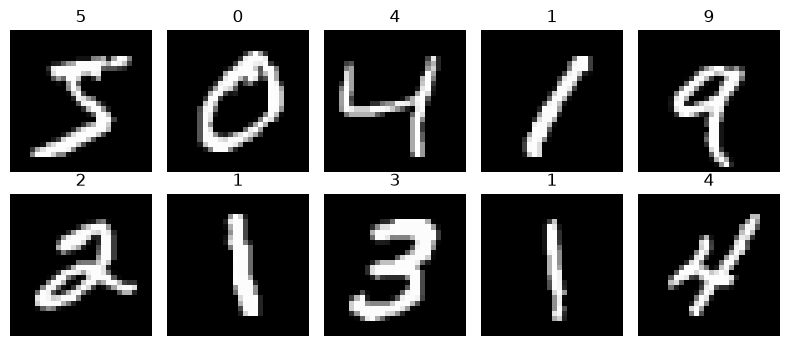

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()


## Pra pengolahan

Pixel dinormalisasi ke 0-1, citra 28x28 di-flatten jadi 784 fitur. Label diubah one-hot. Gak pake ekstraksi fitur tambahan, pixel mentah udah cukup buat ANN.


In [ ]:
# simpan label asli buat evaluasi
y_train_cls = y_train.copy()
y_test_cls = y_test.copy()

X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

X_train = X_train.reshape(-1, 784)
X_test  = X_test.reshape(-1, 784)

y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)

print("X_train:", X_train.shape, "y_train:", y_train.shape)


X_train: (60000, 784) y_train: (60000, 10)


## Model 1 - ReLU

Arsitektur: 784 -> 128 (ReLU) -> 64 (ReLU) -> 10 (softmax). Optimizer Adam, loss categorical crossentropy.


In [ ]:
def buat_model(aktivasi):
    model = models.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(128, activation=aktivasi),
        layers.Dense(64, activation=aktivasi),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_relu = buat_model('relu')
model_relu.summary()


E0000 00:00:1794481618.895816  515862 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Training model ReLU


In [ ]:
hist_relu = model_relu.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)


Epoch 1/10


  1/422 ━━━━━━━━━━━━━━━━━━━━ 4:58 709ms/step - accuracy: 0.0781 - loss: 2.3331

 27/422 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6140 - loss: 1.4661    

 59/422 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7427 - loss: 0.9644

 92/422 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7969 - loss: 0.7486

122/422 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8225 - loss: 0.6497

... (125 outputs left out)

320/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9959 - loss: 0.0180

362/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9959 - loss: 0.0179

403/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9959 - loss: 0.0179

422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9958 - loss: 0.0179 - val_accuracy: 0.9772 - val_loss: 0.0918


## Evaluasi model ReLU


In [ ]:
test_loss, test_acc = model_relu.evaluate(X_test, y_test, verbose=0)
print("Akurasi test ReLU:", round(test_acc, 4))

y_pred = np.argmax(model_relu.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test_cls, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_test_cls, y_pred))


Akurasi test ReLU: 0.9754


              precision    recall  f1-score   support

           0       0.98      0.98      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.98      0.97      0.98      1010
           4       0.97      0.99      0.98       982
           5       0.95      0.98      0.97       892
           6       0.98      0.97      0.97       958
           7       0.99      0.97      0.98      1028
           8       0.95      0.98      0.97       974
           9       0.99      0.95      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

Confusion matrix:
[[ 961    0    3    0    0    3    7    2    4    0]
 [   0 1127    1    0    0    1    2    0    4    0]
 [   3    3  999    2    4    2    3    6   10    0]
 [   0    1    2  980    0   16    0    3    7    1]
 [   1    0

## Grafik training ReLU


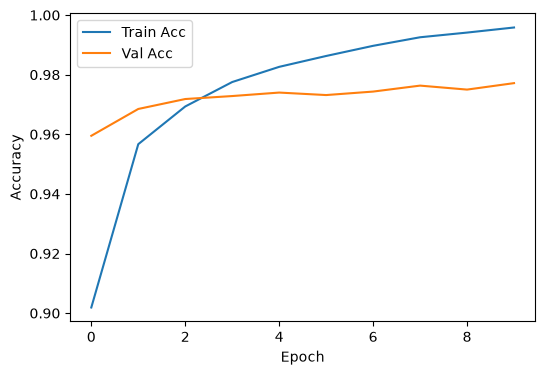

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(hist_relu.history['accuracy'], label='Train Acc')
plt.plot(hist_relu.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


## Bandingin fungsi aktivasi (Tanh)

Arsitektur sama, cuma hidden layer pake tanh.


In [ ]:
model_tanh = buat_model('tanh')

hist_tanh = model_tanh.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

loss_t, acc_t = model_tanh.evaluate(X_test, y_test, verbose=0)
print("Akurasi test Tanh:", round(acc_t, 4))


Epoch 1/10


  1/422 ━━━━━━━━━━━━━━━━━━━━ 3:24 485ms/step - accuracy: 0.1172 - loss: 2.3457

 38/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7366 - loss: 0.9633    

 76/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8086 - loss: 0.7014

116/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8361 - loss: 0.5898

155/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8530 - loss: 0.5286

... (126 outputs left out)

365/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9964 - loss: 0.0197

401/422 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9965 - loss: 0.0197

422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9965 - loss: 0.0196 - val_accuracy: 0.9745 - val_loss: 0.0825


Akurasi test Tanh: 0.9736


## Tabel perbandingan


In [ ]:
relu_val = hist_relu.history['val_accuracy'][-1]
tanh_val = hist_tanh.history['val_accuracy'][-1]

hasil = pd.DataFrame({
    'Aktivasi': ['ReLU', 'Tanh'],
    'Val Acc (epoch 10)': [relu_val, tanh_val],
    'Test Acc': [test_acc, acc_t]
})
hasil


,Aktivasi,Val Acc (epoch 10),Test Acc
0,ReLU,0.977167,0.9754
1,Tanh,0.974500,0.9736


Hasil pengujian menunjukkan bahwa ReLU sedikit lebih baik dibandingkan Tanh, meskipun keduanya sudah mencapai akurasi di atas 0.97. Normalisasi nilai pixel ke rentang 0–1 dan flatten menjadi tahapan preprocessing yang paling berpengaruh. Seleksi fitur tambahan tidak diperlukan karena setiap pixel memiliki informasi yang berguna. Peningkatan performa lebih lanjut bisa dilakukan menggunakan CNN, tetapi ANN tetap dipertahankan karena sudah sesuai dengan brief tugas
